In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from ucimlrepo import fetch_ucirepo
estudiantes_data = fetch_ucirepo(id=697)

In [3]:
estudiantes_data.keys()

dict_keys(['data', 'metadata', 'variables'])

estudiantes_data es un diccionario con claves 'data', 'metadata' y 'variables'. Comenzamos leyendo
metadata para ver qué información nos brinda sobre la base de datos en cuestión.

In [6]:
estudiantes_data['metadata']

{'uci_id': 697,
 'name': "Predict Students' Dropout and Academic Success",
 'repository_url': 'https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success',
 'data_url': 'https://archive.ics.uci.edu/static/public/697/data.csv',
 'abstract': "A dataset created from a higher education institution (acquired from several disjoint databases) related to students enrolled in different undergraduate degrees, such as agronomy, design, education, nursing, journalism, management, social service, and technologies.\nThe dataset includes information known at the time of student enrollment (academic path, demographics, and social-economic factors) and the students' academic performance at the end of the first and second semesters. \nThe data is used to build classification models to predict students' dropout and academic sucess. The problem is formulated as a three category classification task, in which there is a strong imbalance towards one of the classes.",
 'area': 'Soci

Encontramos que tiene 4424 instancias con 36 features cada una. No faltan datos; aparecen variables reales, enteras y categóricas y hay varios datos demográficos. La columna de clases se llama 'Target'. Veamos los nombres de todas las variables.

In [ ]:
estudiantes_data['variables'][['name','description']]

for ind in range(len(estudiantes_data['variables'])):
    print('name', estudiantes_data['variables'].loc[ind,'name'])
    print('description', estudiantes_data['variables'].loc[ind,'description'])

name Marital Status
description 1 – single 2 – married 3 – widower 4 – divorced 5 – facto union 6 – legally separated
name Application mode
description 1 - 1st phase - general contingent 2 - Ordinance No. 612/93 5 - 1st phase - special contingent (Azores Island) 7 - Holders of other higher courses 10 - Ordinance No. 854-B/99 15 - International student (bachelor) 16 - 1st phase - special contingent (Madeira Island) 17 - 2nd phase - general contingent 18 - 3rd phase - general contingent 26 - Ordinance No. 533-A/99, item b2) (Different Plan) 27 - Ordinance No. 533-A/99, item b3 (Other Institution) 39 - Over 23 years old 42 - Transfer 43 - Change of course 44 - Technological specialization diploma holders 51 - Change of institution/course 53 - Short cycle diploma holders 57 - Change of institution/course (International)
name Application order
description Application order (between 0 - first choice; and 9 last choice)
name Course
description 33 - Biofuel Production Technologies 171 - Animat

Nuestro dataset tiene algunas variables numéricas (reales) y otras categóricas. La mayoría de categóricas (que venían como números en el dataset original) pueden ser interpretadas como ordenadas de menor a mayor. Otras no siguen un orden pero, como sólo tienen dos valores posibles, no hay problema en intepretarlas como ordenadas (son 0 o 1). De hecho, nombraremos todas las que interpretamos que realmente no siguen un orden y tienen más de dos valores posibles: Marital status, Application mode, Course, Nationality, Mother's occupation, Father's occupation.

In [19]:
estudiantes_data['data']['features'].head(10)

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,0,5,17,5,11.500000,5,16.2,0.3,-0.92
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,0,8,8,8,14.345000,0,15.5,2.8,-4.06
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,0,5,5,0,0.000000,0,15.5,2.8,-4.06
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,0,6,7,6,14.142857,0,16.2,0.3,-0.92
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,0,6,14,2,13.500000,0,8.9,1.4,3.51


In [33]:
estudiantes_data['data']['original'].columns

Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

Vemos que las tablas 'original' y 'features' se diferencian sólo en que la primera tiene la columna de targets y la segunda no; además, el diccionario de la base de datos también incluye los targets tomados aparte.

Ahora creamos una función para extraer la base de instancias y el target.

In [4]:
from ucimlrepo import fetch_ucirepo

def mapeos_entero_a_categorico(df):
    # --- Mapeos (fuente: Realinho et al. 2021, Features Information) ---
    #Código recibido de Claude
    
    marital_status = {
    1: "single", 2: "married", 3: "widower",
    4: "divorced", 5: "facto_union", 6: "legally_separated"
    }
 
    application_mode = {
    1: "1st_phase_general", 2: "ordinance_612_93",
    5: "1st_phase_azores", 7: "holders_other_higher",
    10: "ordinance_854B_99", 15: "international_bachelor",
    16: "1st_phase_madeira", 17: "2nd_phase_general",
    18: "3rd_phase_general", 26: "ordinance_533A_99_b2",
    27: "ordinance_533A_99_b3", 39: "over_23",
    42: "transfer", 43: "change_course",
    44: "tech_specialization_diploma", 51: "change_institution_course",
    53: "short_cycle_diploma", 57: "change_institution_course_intl"
    }
 
    course = {
    33: "biofuel_production_technologies",
    171: "animation_multimedia_design",
    8014: "social_service_evening",
    9003: "agronomy",
    9070: "communication_design",
    9085: "veterinary_nursing",
    9119: "informatics_engineering",
    9130: "equinculture",
    9147: "management",
    9238: "social_service",
    9254: "tourism",
    9500: "nursing",
    9556: "oral_hygiene",
    9670: "advertising_marketing_management",
    9773: "journalism_communication",
    9853: "basic_education",
    9991: "management_evening"
    }
 
    daytime_evening = {1: "daytime", 0: "evening"}
 
    previous_qualification = {
    1: "secondary_education",
    2: "higher_bachelor",
    3: "higher_degree",
    4: "higher_master",
    5: "higher_doctorate",
    6: "higher_education_frequency",
    9: "12th_year_not_completed",
    10: "11th_year_not_completed",
    12: "other_11th_year",
    14: "10th_year",
    15: "10th_year_not_completed",
    19: "basic_3rd_cycle",
    38: "basic_2nd_cycle",
    39: "tech_specialization_course",
    40: "higher_degree_1st_cycle",
    42: "professional_higher_technical",
    43: "higher_master_2nd_cycle"
    }
 
    nationality = {
    1: "portuguese", 2: "german", 6: "spanish", 11: "italian",
    13: "dutch", 14: "english", 17: "lithuanian", 21: "angolan",
    22: "cape_verdean", 24: "guinean", 25: "mozambican",
    26: "santomean", 32: "turkish", 41: "brazilian",
    62: "romanian", 100: "moldovan", 101: "mexican",
    103: "ukrainian", 105: "russian", 108: "cuban", 109: "colombian"
    }
 
# Madre y padre comparten el mismo esquema de calificación
    qualification = {
    1: "secondary_12th", 2: "higher_bachelor", 3: "higher_degree",
    4: "higher_master", 5: "higher_doctorate",
    6: "higher_education_frequency", 9: "12th_not_completed",
    10: "11th_not_completed", 11: "7th_year_old",
    12: "other_11th", 13: "2nd_year_complementary",
    14: "10th_year", 18: "general_commerce",
    19: "basic_3rd_cycle", 20: "complementary_high_school",
    22: "technical_professional", 25: "complementary_not_concluded",
    26: "7th_year", 27: "2nd_cycle_general_high_school",
    29: "9th_not_completed", 30: "8th_year",
    31: "general_admin_commerce", 33: "supplementary_accounting",
    34: "unknown", 35: "cannot_read_write",
    36: "can_read_no_4th_year", 37: "basic_1st_cycle",
    38: "basic_2nd_cycle", 39: "tech_specialization",
    40: "higher_degree_1st_cycle", 41: "specialized_higher_studies",
    42: "professional_higher_technical", 43: "higher_master_2nd_cycle",
    44: "higher_doctorate_3rd_cycle"
    }
 
# Madre y padre comparten el mismo esquema de ocupación
    occupation = {
    0: "student",
    1: "legislative_directors",
    2: "intellectual_scientific_specialists",
    3: "intermediate_technicians",
    4: "administrative_staff",
    5: "personal_services_sellers",
    6: "agriculture_fisheries_forestry",
    7: "skilled_industry_construction",
    8: "machine_operators_assembly",
    9: "unskilled_workers",
    10: "armed_forces",
    90: "other",
    99: "blank",
    101: "armed_forces_officers",
    102: "armed_forces_sergeants",
    103: "other_armed_forces",
    112: "admin_commercial_directors",
    114: "hotel_trade_directors",
    121: "physical_math_engineering_specialists",
    122: "health_professionals",
    123: "teachers",
    124: "finance_accounting_specialists",
    125: "ict_specialists",
    131: "science_engineering_technicians",
    132: "health_technicians",
    134: "legal_social_sports_technicians",
    135: "ict_technicians",
    141: "office_workers_secretaries",
    143: "data_accounting_operators",
    144: "other_admin_support",
    151: "personal_service_workers",
    152: "sellers",
    153: "personal_care_workers",
    154: "protection_security",
    161: "market_oriented_farmers",
    163: "subsistence_farmers",
    171: "skilled_construction_workers",
    172: "metallurgy_metalworking",
    173: "printing_precision_jewelers",
    174: "electricity_electronics",
    175: "food_woodworking_clothing",
    181: "fixed_plant_operators",
    182: "assembly_workers",
    183: "vehicle_drivers",
    191: "cleaning_workers",
    192: "unskilled_agriculture",
    193: "unskilled_extractive_construction",
    194: "meal_preparation_assistants",
    195: "street_vendors"
    }
 
    gender = {1: "male", 0: "female"}
    binary_yes_no = {1: "yes", 0: "no"}
 
 
# --- Conversiones ---
    df["Marital Status"] = df["Marital Status"].map(marital_status)
    df["Application mode"] = df["Application mode"].map(application_mode)
    df["Course"] = df["Course"].map(course)
    df["Daytime/evening attendance"] = df["Daytime/evening attendance"].map(daytime_evening)
    df["Previous qualification"] = df["Previous qualification"].map(previous_qualification)
    df["Nacionality"] = df["Nacionality"].map(nationality)
    df["Mother's qualification"] = df["Mother's qualification"].map(qualification)
    df["Father's qualification"] = df["Father's qualification"].map(qualification)
    df["Mother's occupation"] = df["Mother's occupation"].map(occupation)
    df["Father's occupation"] = df["Father's occupation"].map(occupation)
    df["Gender"] = df["Gender"].map(gender)
    df["Displaced"] = df["Displaced"].map(binary_yes_no)
    df["Educational special needs"] = df["Educational special needs"].map(binary_yes_no)
    df["Debtor"] = df["Debtor"].map(binary_yes_no)
    df["Tuition fees up to date"] = df["Tuition fees up to date"].map(binary_yes_no)
    df["Scholarship holder"] = df["Scholarship holder"].map(binary_yes_no)
    df["International"] = df["International"].map(binary_yes_no)

def get_data():
    estudiantes_data = fetch_ucirepo(id=697)
    X = estudiantes_data['data']['features']
    mapeos_entero_a_categorico(X)
    y = estudiantes_data['data']['targets']
    return X,y

In [5]:
X,y = get_data()

C:\Users\Lenny\AppData\Local\Temp\ipykernel_4244\793322455.py:154: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Marital Status"] = df["Marital Status"].map(marital_status)
C:\Users\Lenny\AppData\Local\Temp\ipykernel_4244\793322455.py:155: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Application mode"] = df["Application mode"].map(application_mode)
C:\Users\Lenny\AppData\Local\Temp\ipykernel_4244\793322455.py:156: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Data

In [4]:
y

,Target
0,Dropout
1,Graduate
2,Dropout
3,Graduate
4,Graduate
...,...
4419,Graduate
4420,Dropout
4421,Dropout
4422,Graduate


Verificamos que no hayan quedado datos sin mapear:

In [6]:
X.isnull().sum() #correcto

Marital Status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

Ahora verificamos el grado de balance entre las tres clases, ya que si hubiera un gran desbalance sería necesario tomar medidas al respecto durante el desarrollo.

In [7]:
from collections import Counter
print(Counter(y['Target']))
print('% dropout: ',(1421/4424)*100)
print('% graduate: ',(2209/4424)*100)
print('% enrolled: ',(794/4424)*100)

Counter({'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794})
% dropout:  32.120253164556964
% graduate:  49.93218806509946
% enrolled:  17.94755877034358


Vemos que la mitad se gradúan, un 18% continúan y un 32% abandonan. No hay un desbalance notorio de clases.

Continuamos ahora estudiando la semántica de los atributos y decidiendo qué tipos de atributos hay.
Podemos ver más arriba en el nombre y descripción que los features incluyen:
datos personales (como estado civil y nacionalidad)
datos familiares (educación y ocupación de los padres)
datos de inscripción (modalidad y orden)
datos académicos (materias cursadas, rendidas y notas por semestre, nota del examen de ingreso)
datos macroeconómicos (GDP e inflación)
datos de la economía personal del estudiante (si es deudor o no, si tiene la matrícula al día, empleo)

Antes de ponernos a construir modelos, vamos a realizar un análisis exploratorio con tres hipótesis de trabajo:
1) Hay relación directa entre los indicadores de desempeño académico y el hecho de que los estudiantes se gradúen o no (por ejemplo, tienen que haber rendido y aprobado muchas materias para graduarse).
2) El desempeño académico y la situación económica personal del estudiante son predictores de abandono muy superiores al resto de los features.
3) Puede tener alguna influencia el género, o el género combinado con el estado civil (principalmente si están casados o no).
4) Puede haber materias "fáciles" y materias "difíciles" que influyan un poco en el abandono.

Realizaremos algunos gráficos para corroborar estas hipótesis. Además, creemos que para predecir la clase no alcanza mirar de forma aislada cuántas materias cursó el estudiante, cuántos exámenes rindió o cuántos aprobó, sino todas estas variables integralmente (¿cursó poco o mucho pero aprobó todo? ¿O suele abandonar materias?).

In [53]:
X[['Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd sem (grade)',
       'Curricular units 2nd sem (without evaluations)']].head(50)

,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations)
0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0
1,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0
2,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0
3,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0
4,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0
5,0,5,10,5,11.857143,0,0,5,17,5,11.500000,5
6,0,7,9,7,13.300000,0,0,8,8,8,14.345000,0
7,0,5,5,0,0.000000,0,0,5,5,0,0.000000,0
8,0,6,8,6,13.875000,0,0,6,7,6,14.142857,0
9,0,6,9,5,11.400000,0,0,6,14,2,13.500000,0


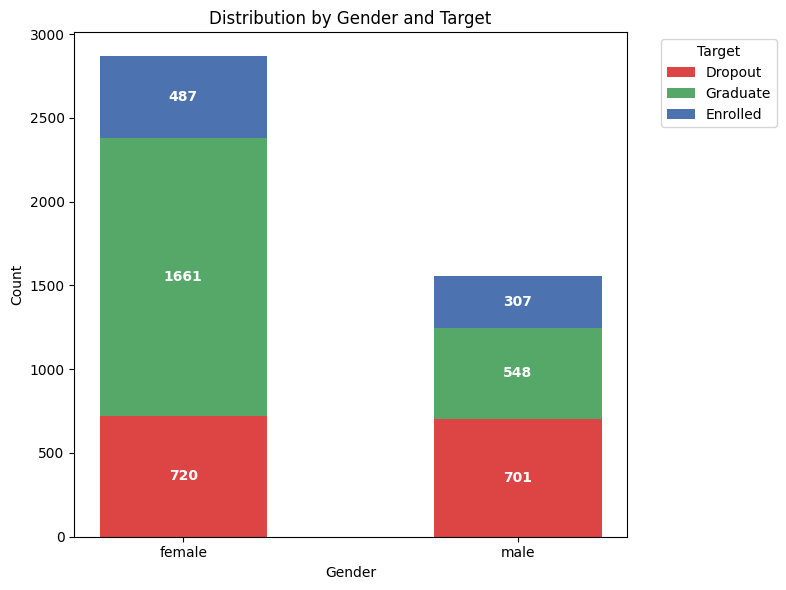

In [6]:
# Contar combinaciones Gender + Target
X_con_target = X.copy()
X_con_target['Target'] = y['Target']
gender_target_counts = (
    X_con_target.groupby(['Gender', 'Target'])
    .size()
    .unstack(fill_value=0)
)

# Reordenar columnas por si acaso
target_values = ['Dropout', 'Graduate', 'Enrolled']

# Configuración del gráfico
fig, ax = plt.subplots(figsize=(8, 6))

genders = gender_target_counts.index.tolist()
x = np.arange(len(genders))
bar_width = 0.5
colors = ['#DD4444', '#55A868', '#4C72B0']

# Barras apiladas
bottom = np.zeros(len(genders))
for i, target_val in enumerate(target_values):
    values = gender_target_counts[target_val].values
    bars = ax.bar(x, values, bar_width, bottom=bottom,
                  label=target_val, color=colors[i])

    # Etiquetas dentro de cada segmento
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                str(val),
                ha='center', va='center',
                fontsize=10, color='white', fontweight='bold'
            )
    bottom += values

# Etiquetas y formato
ax.set_xticks(x)
ax.set_xticklabels(genders)
ax.set_xlabel('Gender')
ax.set_ylabel('Count')
ax.set_title('Distribution by Gender and Target')
ax.legend(title='Target', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#Notamos que en total hay 2868 mujeres y 1556 varones.

In [7]:
# Contar combinaciones feature + Target
def grafico_barras_por_clase(df,feature):
    feature_target_counts = (
        X_con_target.groupby([feature, 'Target'])
        .size()
        .unstack(fill_value=0)
    )

# Ordenar cursos por total descendente (opcional pero recomendado)
    feature_target_counts['Total'] = feature_target_counts.sum(axis=1)
    feature_target_counts = feature_target_counts.sort_values('Total', ascending=False)
    feature_target_counts = feature_target_counts.drop(columns='Total')

# Configuración del gráfico
    n_courses = len(feature_target_counts)
    fig, ax = plt.subplots(figsize=(max(12, n_courses * 0.8), 7))

    courses = feature_target_counts.index.tolist()
    x = np.arange(n_courses)
    bar_width = 0.6
    colors = ['#DD4444', '#55A868', '#4C72B0']  # Rojo=Dropout, Verde=Graduate, Azul=Enrolled

    # Barras apiladas
    bottom = np.zeros(n_courses)
    for i, target_val in enumerate(target_values):
        values = feature_target_counts[target_val].values
        bars = ax.bar(x, values, bar_width, bottom=bottom,
                  label=target_val, color=colors[i])

    # Etiquetas dentro de cada segmento (solo si el segmento es suficientemente grande)
        for bar, val in zip(bars, values):
            if val > 20:  # Ajusta este umbral según tus datos
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    str(val),
                    ha='center', va='center',
                    fontsize=7, color='white', fontweight='bold'
                )
        bottom += values

    # Etiquetas y formato
    ax.set_xticks(x)
    ax.set_xticklabels(courses, rotation=45, ha='right', fontsize=8)
    ax.set_xlabel(feature)
    ax.set_ylabel('Count')
    ax.set_title('Distribution by' + feature + ' and Target')
    ax.legend(title='Target', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

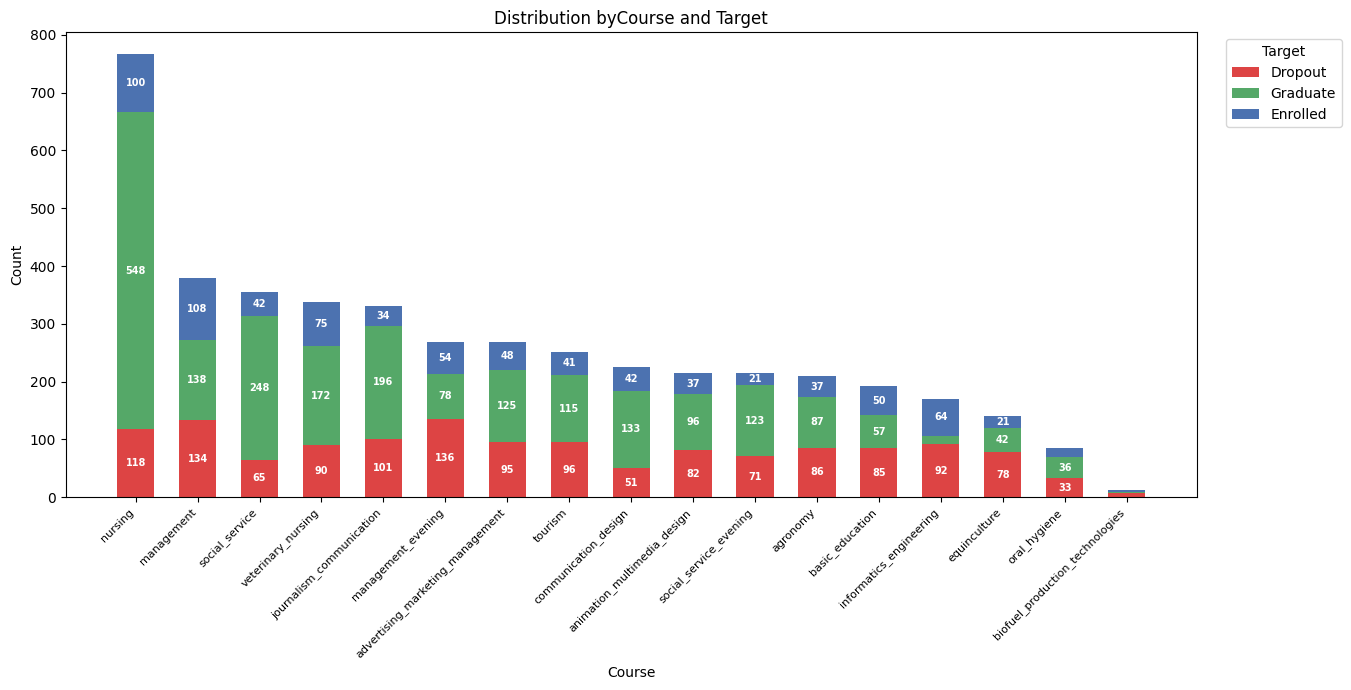

In [12]:
grafico_barras_por_clase(X_con_target,'Course')

En este gráfico observamos que la materia claramente mayoritaria es Nursing, además de ser con diferencia la de menor tasa de abandono. Por otro lado, algunas de las materias con mayor tasa de abandono son Informatics Engineering, Equinculture y Management evening. Es posible que Nursing sea una materia con amplia mayoría de mujeres, lo que podría explicar la diferencia que antes vimos en las tasas de abandono por género. Procedemos a verificarlo.

In [13]:
X_nursing = X_con_target[X_con_target['Course'] == 'nursing']
X_nursing.groupby(['Gender']).count()[['Course']]

,Course
Gender,
female,617
male,149


Efectivamente, vemos que alrededor del 80% de alumnos de Nursing son mujeres. Interpretamos que hay una conexión directa entre este hecho y la menor tasa de abandono en mujeres, por lo que no queda claro si es más influyente el género o la materia que se cursa. Vamos a estudiar esto graficando las tasas de deserción por género sin la materia Nursing.

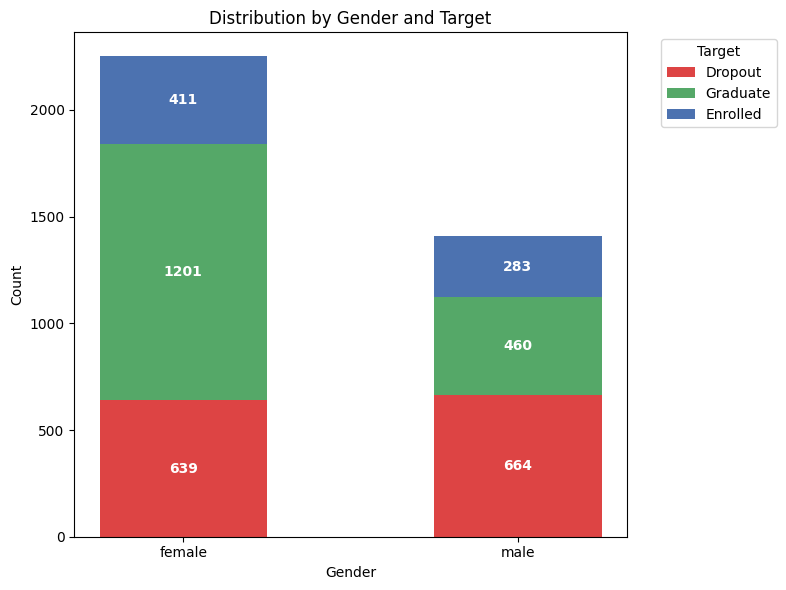

In [14]:
X_con_target_sin_nursing = X_con_target[X_con_target['Course'] != 'nursing']
gender_target_counts = (
    X_con_target_sin_nursing.groupby(['Gender', 'Target'])
    .size()
    .unstack(fill_value=0)
)

# Reordenar columnas por si acaso
target_values = ['Dropout', 'Graduate', 'Enrolled']

# Configuración del gráfico
fig, ax = plt.subplots(figsize=(8, 6))

genders = gender_target_counts.index.tolist()
x = np.arange(len(genders))
bar_width = 0.5
colors = ['#DD4444', '#55A868', '#4C72B0']

# Barras apiladas
bottom = np.zeros(len(genders))
for i, target_val in enumerate(target_values):
    values = gender_target_counts[target_val].values
    bars = ax.bar(x, values, bar_width, bottom=bottom,
                  label=target_val, color=colors[i])

    # Etiquetas dentro de cada segmento
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                str(val),
                ha='center', va='center',
                fontsize=10, color='white', fontweight='bold'
            )
    bottom += values

# Etiquetas y formato
ax.set_xticks(x)
ax.set_xticklabels(genders)
ax.set_xlabel('Gender')
ax.set_ylabel('Count')
ax.set_title('Distribution by Gender and Target')
ax.legend(title='Target', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#Sin la materia Nursing, hay 2251 mujeres y 1407 varones.

Incluso sin contar Nursing, las cantidades de abandono por género son parejas a pesar de que hay alrededor de un 50% más de mujeres. Concluimos que la tasa de abandono es mejor explicada por el género que por el hecho de estar cursando la materia con menor tasa de abandono u otras. Concretamente, las mujeres parecen abandonar menos.

In [8]:
def scatter_plot_by_target(df: pd.DataFrame, x_attr: str, y_attr: str):
    """
    Genera un scatter plot coloreado según el valor de la columna 'Target'.

    Parámetros:
        df      : DataFrame de Pandas con los datos.
        x_attr  : Nombre del atributo para el eje horizontal.
        y_attr  : Nombre del atributo para el eje vertical.
    """
    color_map = {
        "Dropout":  "#E74C3C",   # rojo
        "Graduate": "#2ECC71",   # verde
        "Enrolled": "#3498DB",   # azul
    }

    fig, ax = plt.subplots(figsize=(9, 6))

    for target_value, group in df.groupby("Target"):
        color = color_map.get(target_value, "#95A5A6")   # gris si hay valor inesperado
        ax.scatter(
            group[x_attr],
            group[y_attr],
            label=target_value,
            color=color,
            alpha=0.6,
            edgecolors="white",
            linewidths=0.4,
            s=60,
        )

    ax.set_xlabel(x_attr, fontsize=12)
    ax.set_ylabel(y_attr, fontsize=12)
    ax.set_title(f"{x_attr}  vs  {y_attr}", fontsize=14)
    ax.legend(title="Target", fontsize=10, title_fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

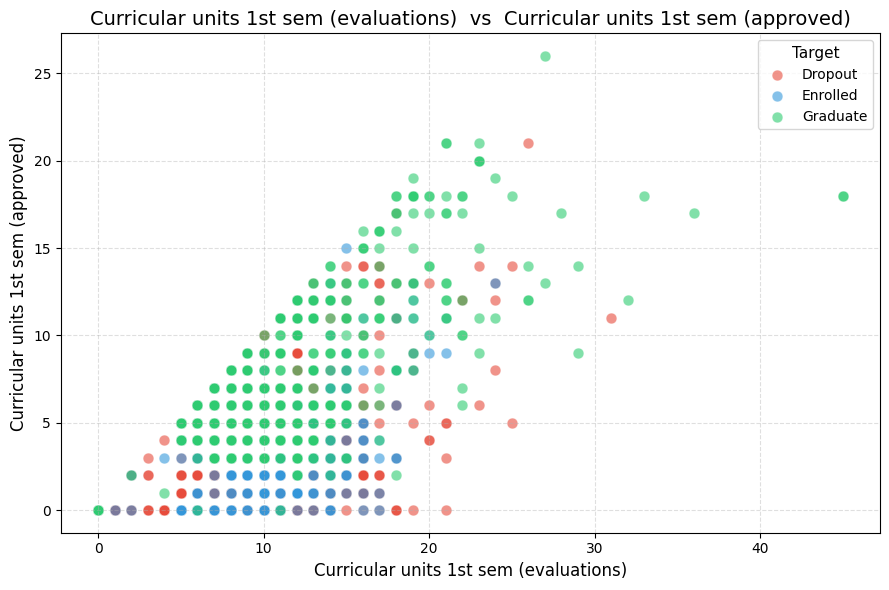

In [31]:
scatter_plot_by_target(X_con_target,'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)')

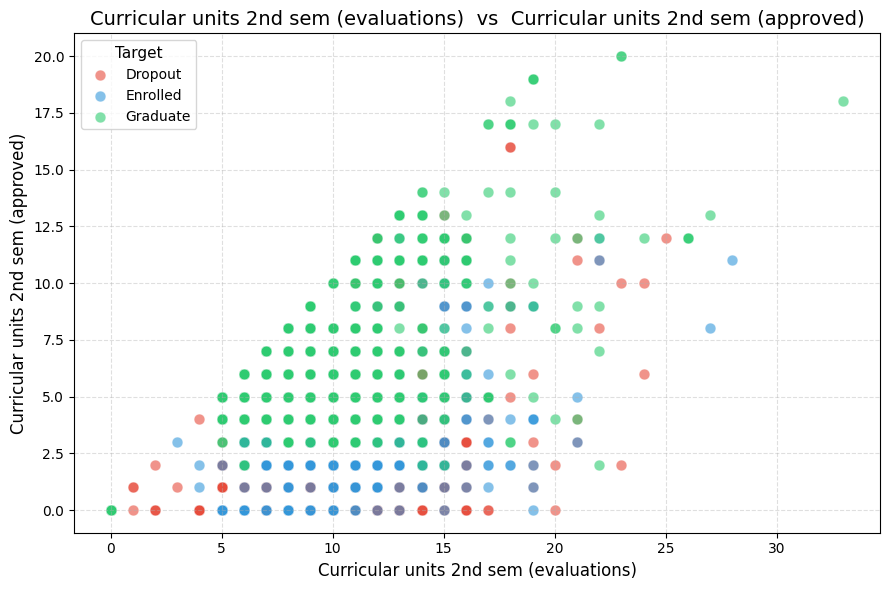

In [17]:
scatter_plot_by_target(X_con_target,'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',)
#Si quitamos los graduados, los exámenes rendidos van de 0 a 25 aprox y los aprobados, de 0 a 16
#Con los graduados, hay hasta 20 exámenes aprobados

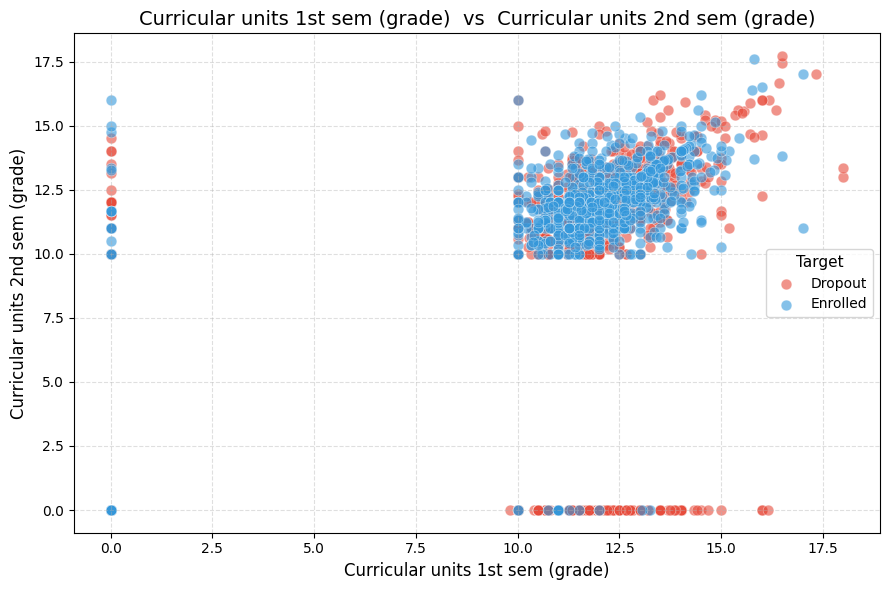

In [ ]:
#Estos atributos también tienen poca capacidad predictiva, que se revela al sacar los graduados
scatter_plot_by_target(X_con_target[X_con_target['Target'] != 'Graduate'],'Curricular units 1st sem (grade)',
       'Curricular units 2nd sem (grade)')
#scatter_plot_by_target(X_con_target,'Curricular units 1st sem (grade)',
#       'Curricular units 2nd sem (grade)')
#Sí se puede ver que aquellos con 0 (o que no rindieron) en el 2do semestre no se gradúan

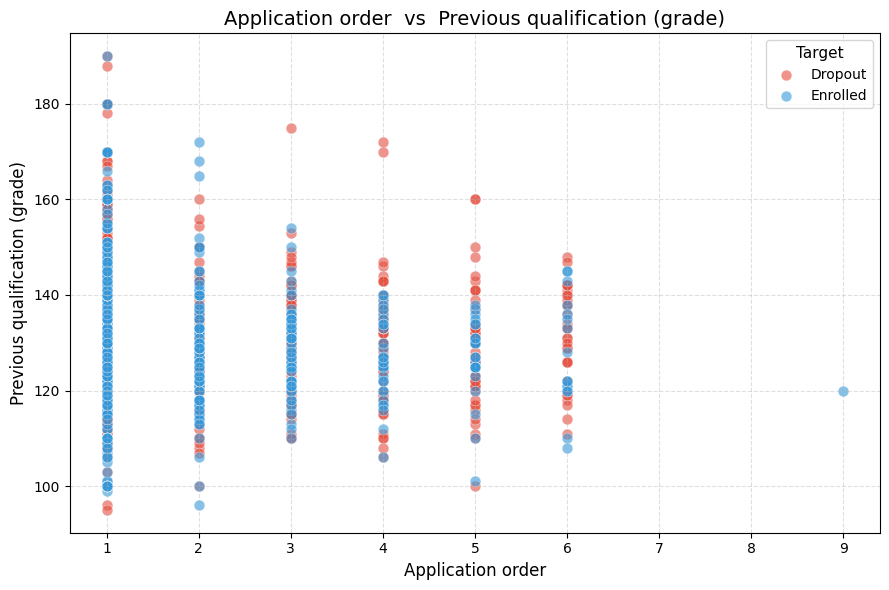

In [19]:
#Se revela una menor capacidad predictiva de estos atributos cuando quitamos los graduados (que
#destacan por ser la clase mayoritaria)
scatter_plot_by_target(X_con_target[X_con_target['Target'] != 'Graduate'], 'Application order','Previous qualification (grade)')

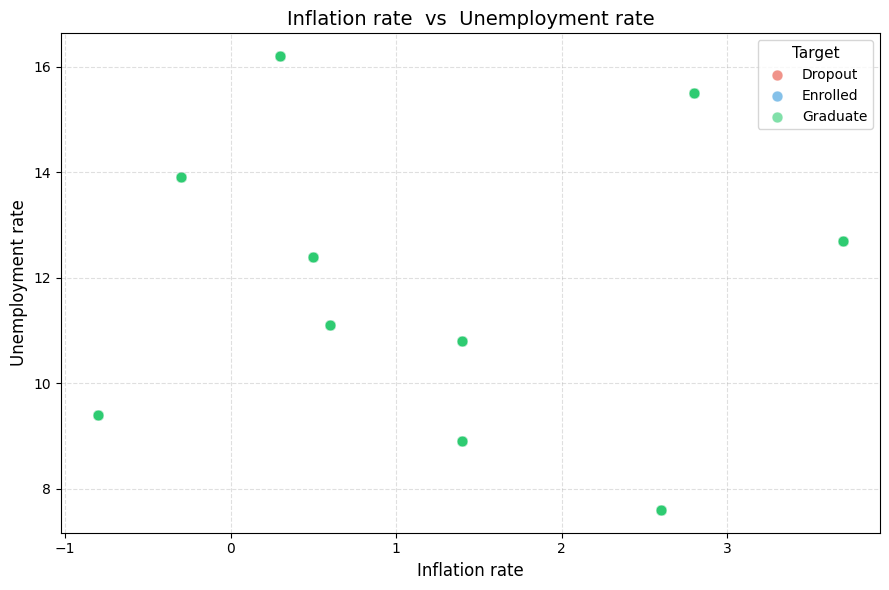

array([ 1.4, -0.3, -0.8,  0.3,  2.8,  3.7,  0.6,  2.6,  0.5])

In [14]:
scatter_plot_by_target(X_con_target,'Inflation rate',
       'Unemployment rate')
X_con_target['Unemployment rate'].unique()
X_con_target['Inflation rate'].unique()


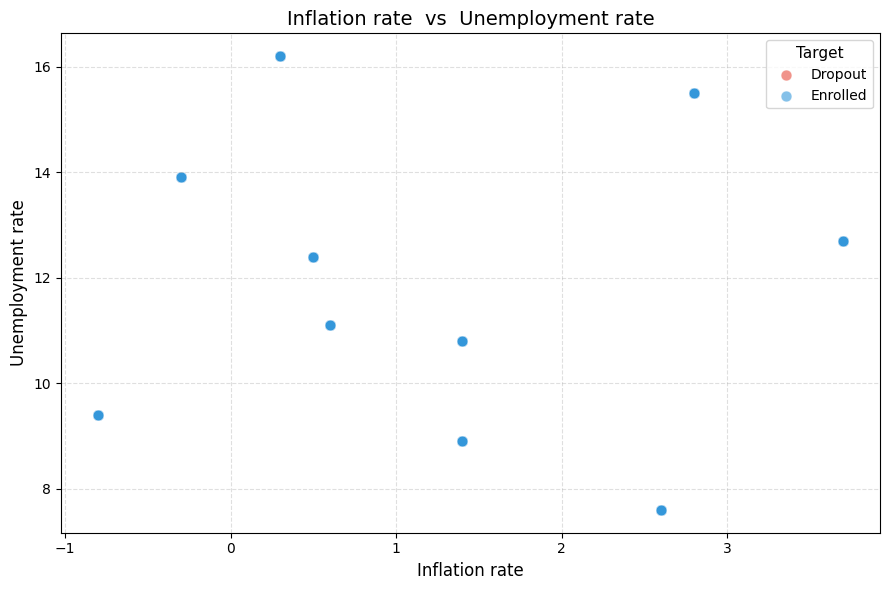

In [15]:
scatter_plot_by_target(X_con_target[X_con_target['Target'] != 'Graduate'],'Inflation rate',
       'Unemployment rate')


Los features Unemployment rate e Inflation rate no tienen ningún valor predictivo porque sólo tienen 10 y 9 valores diferentes respectivamente. En el gráfico todos los puntos se ven verdes porque hay mayoría de graduados.

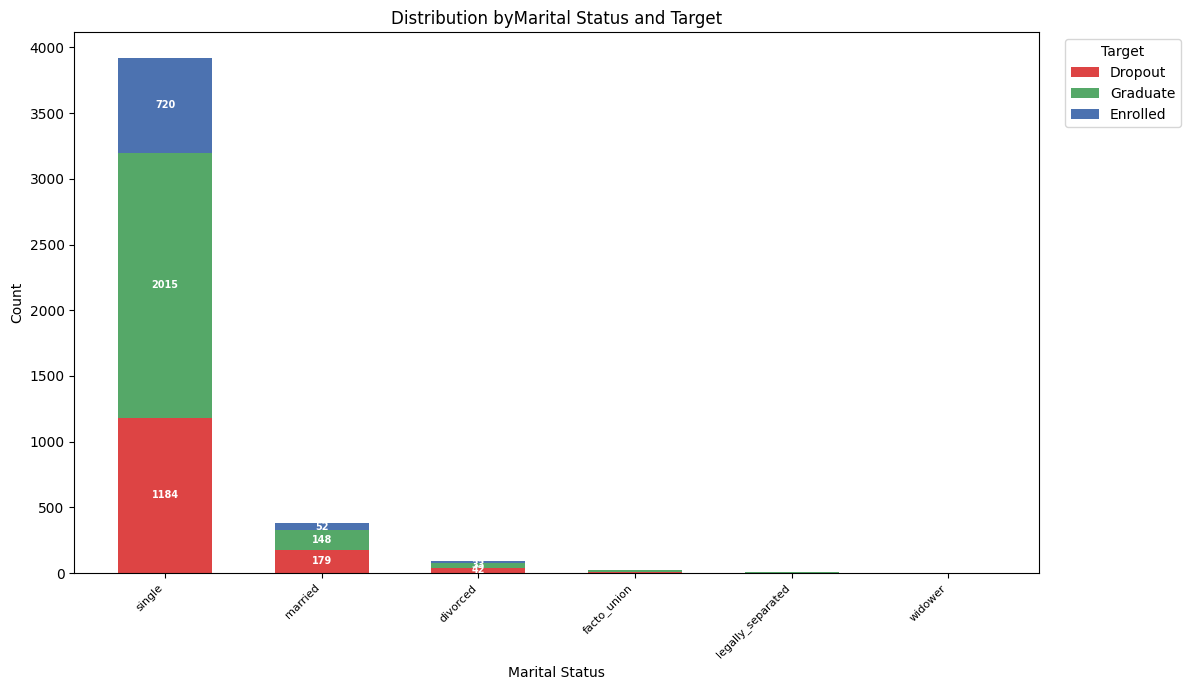

In [20]:
grafico_barras_por_clase(X_con_target,'Marital Status')

Se observa que abandonan cerca de la mitad de los casados y menos del 30% de los solteros, lo que marca una influencia apreciable del estado civil. Deducimos que las personas casadas tienden a dejar sus estudios para priorizar lo familiar. En los otros estados civiles hay muy pocas muestras como para tomar una decisión.

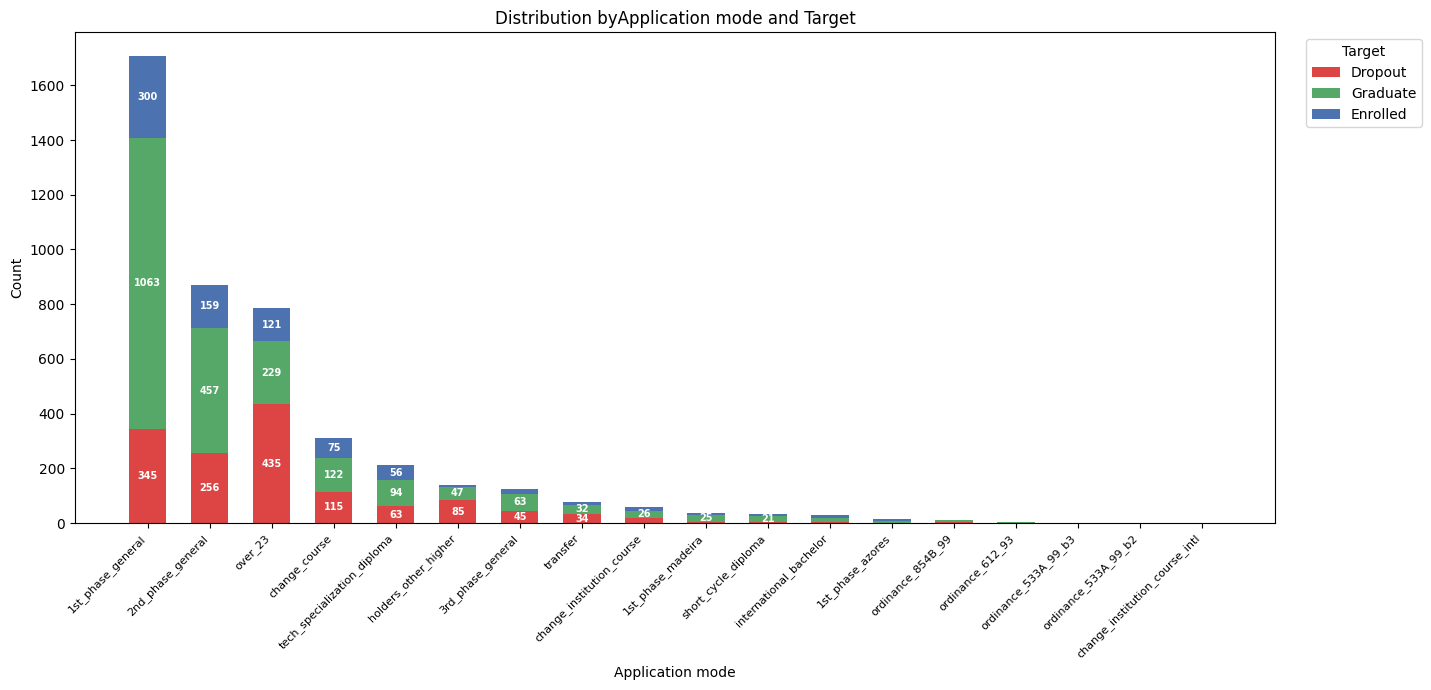

In [21]:
grafico_barras_por_clase(X_con_target,'Application mode')

El application mode con mayor deserción es over_23 (interpretamos que son alumnos mayores de 23 años, posiblemente ya con trabajo).

A continuación estudiamos si la situación económica del estudiante influye de forma notable.

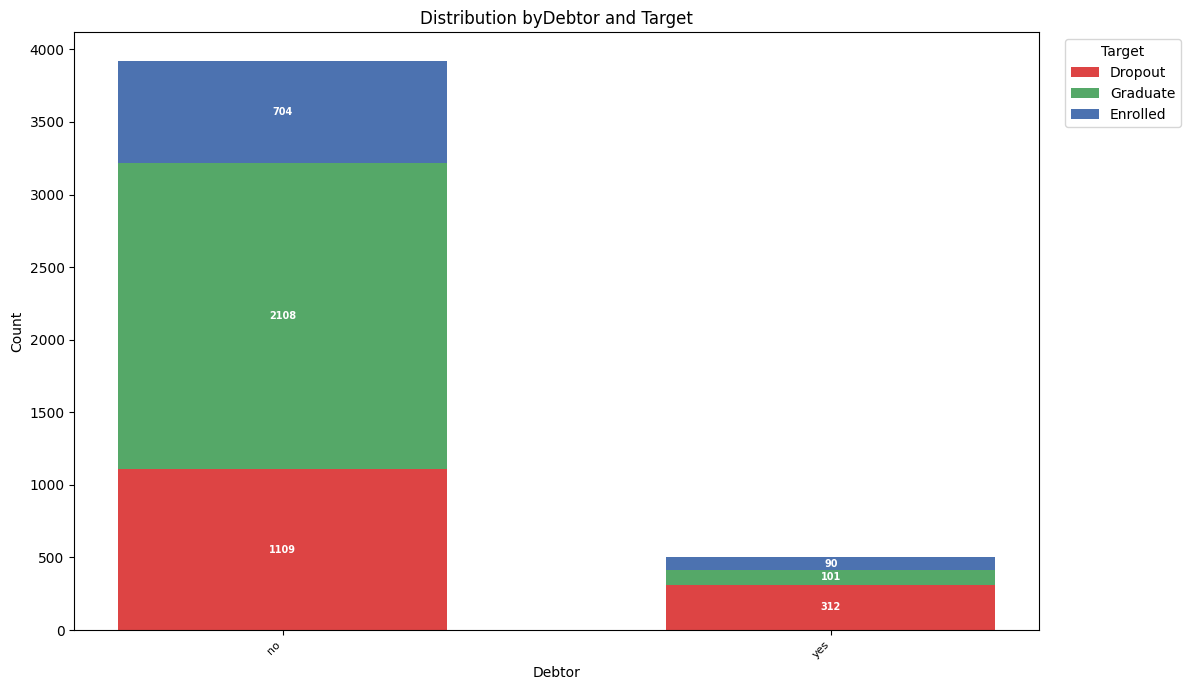

In [22]:
"""
name Debtor
description 1 – yes 0 – no
name Tuition fees up to date
description 1 – yes 0 – no
"""
grafico_barras_por_clase(X_con_target,'Debtor')

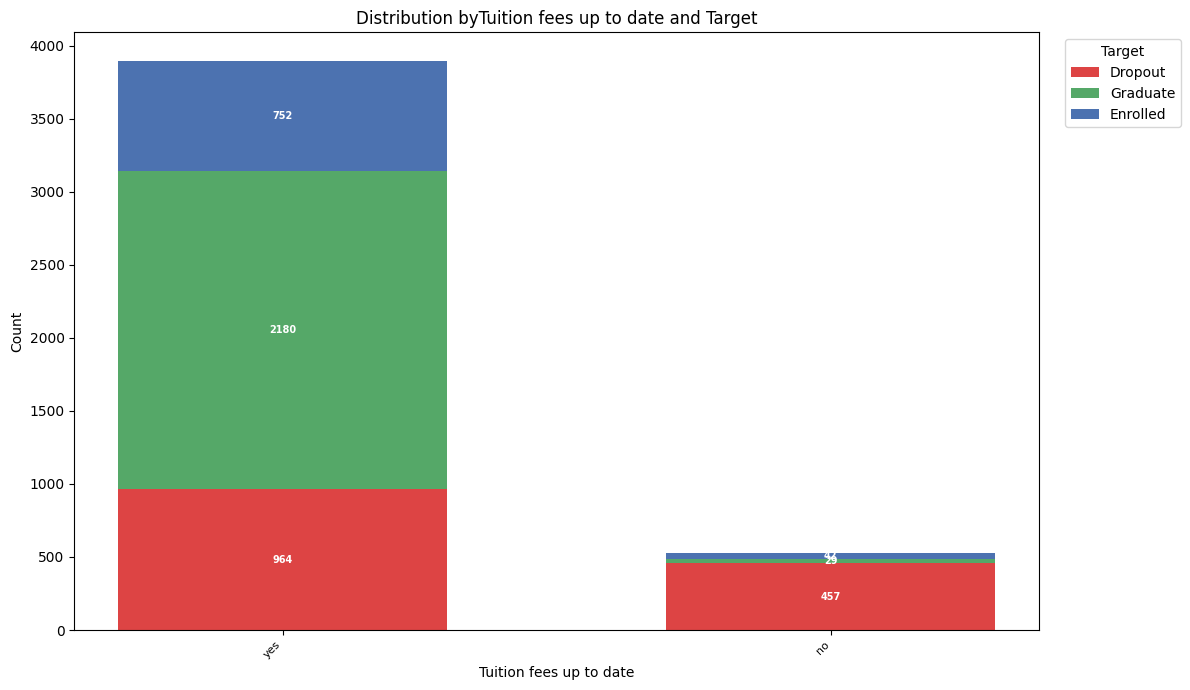

In [23]:
grafico_barras_por_clase(X_con_target,'Tuition fees up to date')

Estas últimas dos variables demuestran ser algunas de las más importantes para predecir abandono. No hay una equivalencia entre alguno de sus valores y el abandono, pero se observa porcentajes de abandono altísimos cuando "Tuition fees up to date" es No (matrícula no pagada), y uno superior al 60% para deudores (en cambio, los porcentajes de deserción son relativamente bajos en los grupos). Es indispensable tener en cuenta estas variables en el estudio.

Vamos a reevaluar la importancia relativa de estos indicadores económicos repitiendo varios de los gráficos anteriores sin los deudores y los que no pagan cuota.

In [37]:
X_economia_limpia = X_con_target[X_con_target['Debtor'] == 'no']
X_economia_limpia = X_economia_limpia[X_economia_limpia['Tuition fees up to date'] == 'yes']
X_economia_limpia

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,single,2nd_phase_general,5,animation_multimedia_design,daytime,secondary_education,122.0,portuguese,basic_3rd_cycle,other_11th,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,single,2nd_phase_general,2,journalism_communication,daytime,secondary_education,122.0,portuguese,basic_2nd_cycle,basic_1st_cycle,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,married,over_23,1,social_service_evening,evening,secondary_education,100.0,portuguese,basic_1st_cycle,basic_2nd_cycle,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
6,single,1st_phase_general,1,nursing,daytime,secondary_education,142.0,portuguese,basic_3rd_cycle,basic_2nd_cycle,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
8,single,1st_phase_general,3,social_service,daytime,secondary_education,137.0,romanian,secondary_12th,secondary_12th,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4418,single,tech_specialization_diploma,1,communication_design,daytime,tech_specialization_course,120.0,portuguese,higher_degree,basic_2nd_cycle,...,5,9,10,7,13.142857,1,16.2,0.3,-0.92,Graduate
4419,single,1st_phase_general,6,journalism_communication,daytime,secondary_education,125.0,portuguese,secondary_12th,secondary_12th,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4421,single,1st_phase_general,1,nursing,daytime,secondary_education,154.0,portuguese,basic_1st_cycle,basic_1st_cycle,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,single,1st_phase_general,1,management,daytime,secondary_education,180.0,portuguese,basic_1st_cycle,basic_1st_cycle,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


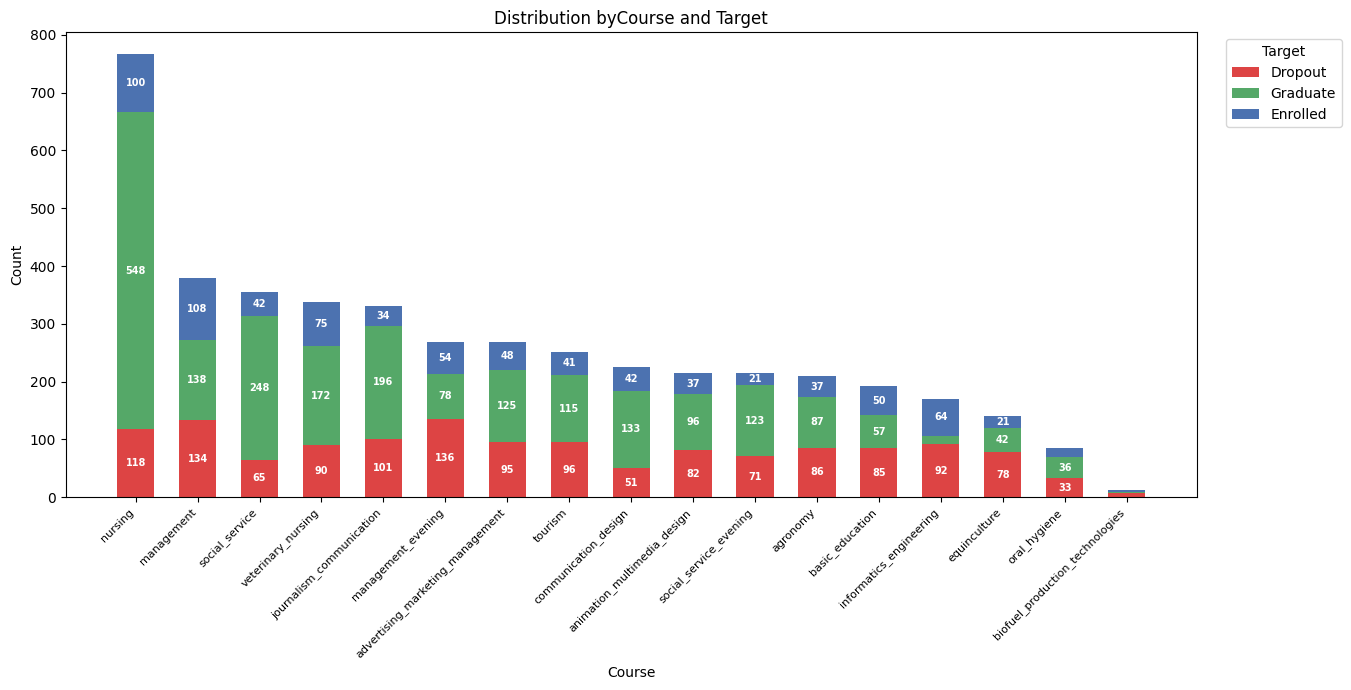

In [38]:
grafico_barras_por_clase(X_economia_limpia,'Course')
#No se observa una alteración importante por este feature.

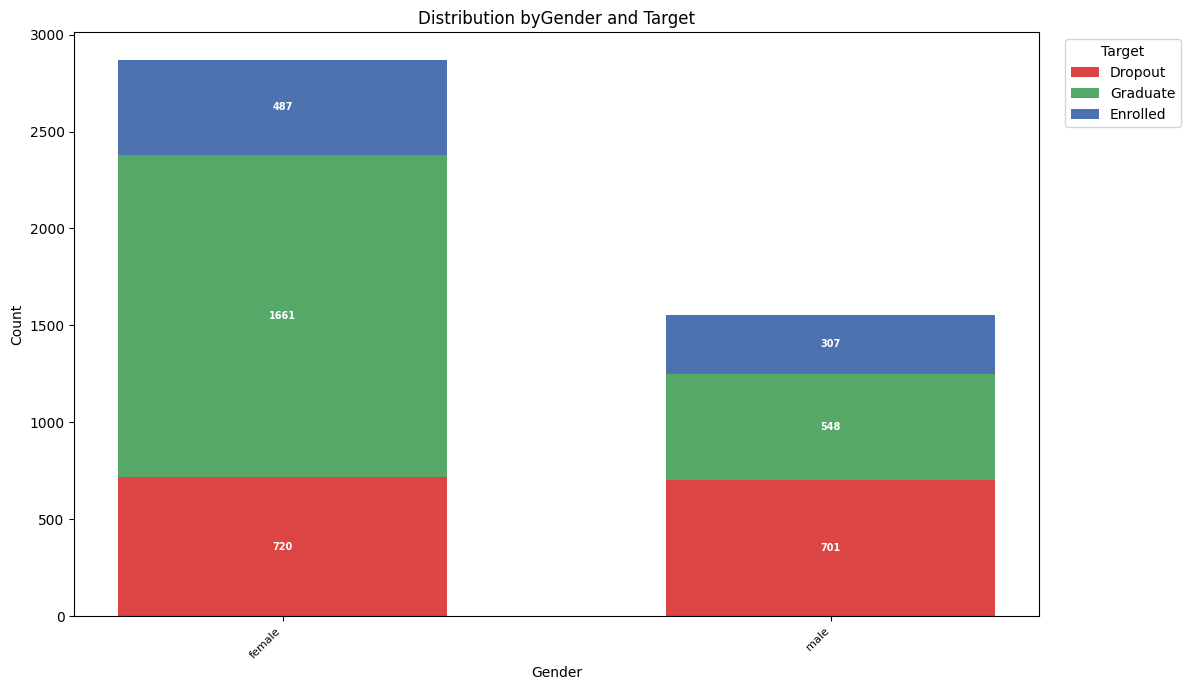

In [39]:
grafico_barras_por_clase(X_economia_limpia,'Gender')
#Tampoco por este, se observa la misma dinámica donde las mujeres abandonan mucho menos.

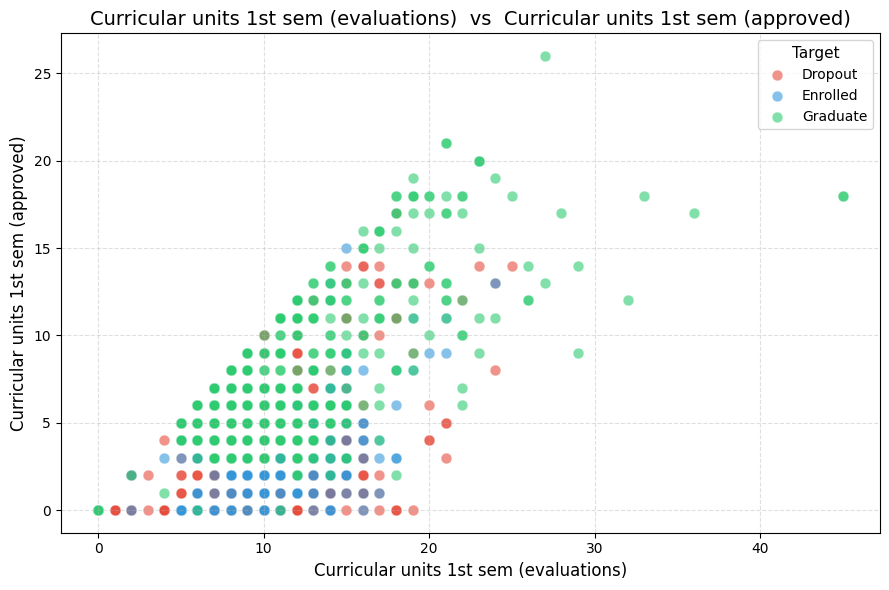

In [42]:
scatter_plot_by_target(X_economia_limpia,'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)')

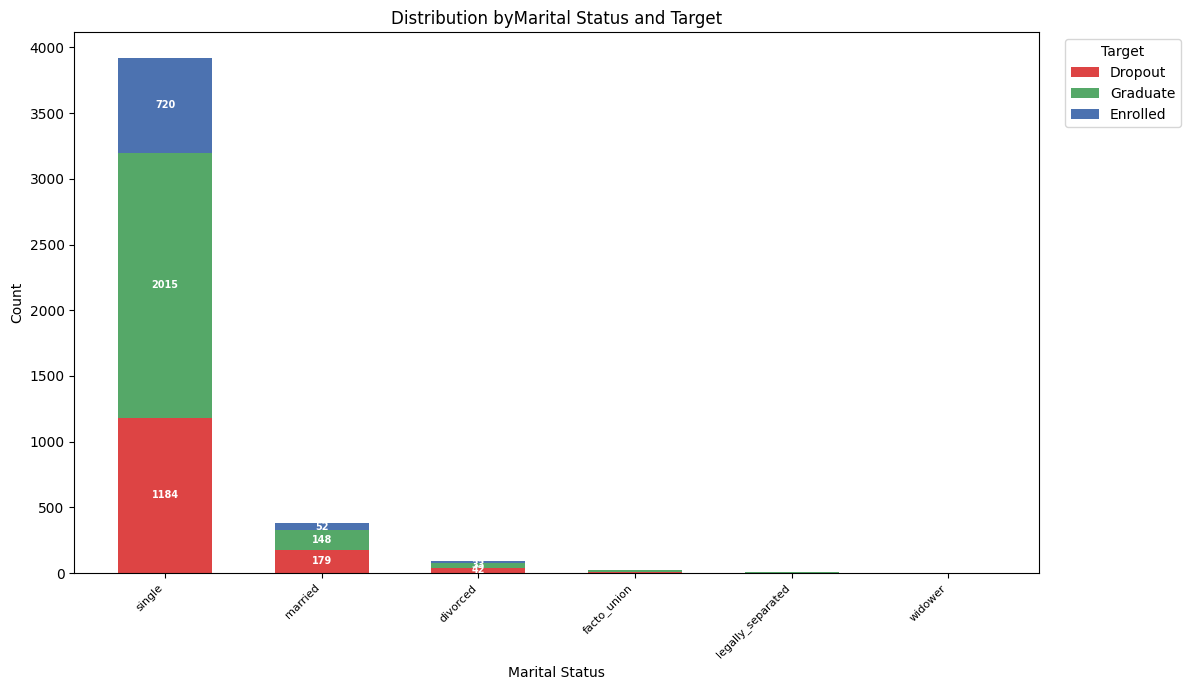

In [43]:
grafico_barras_por_clase(X_economia_limpia,'Marital Status')

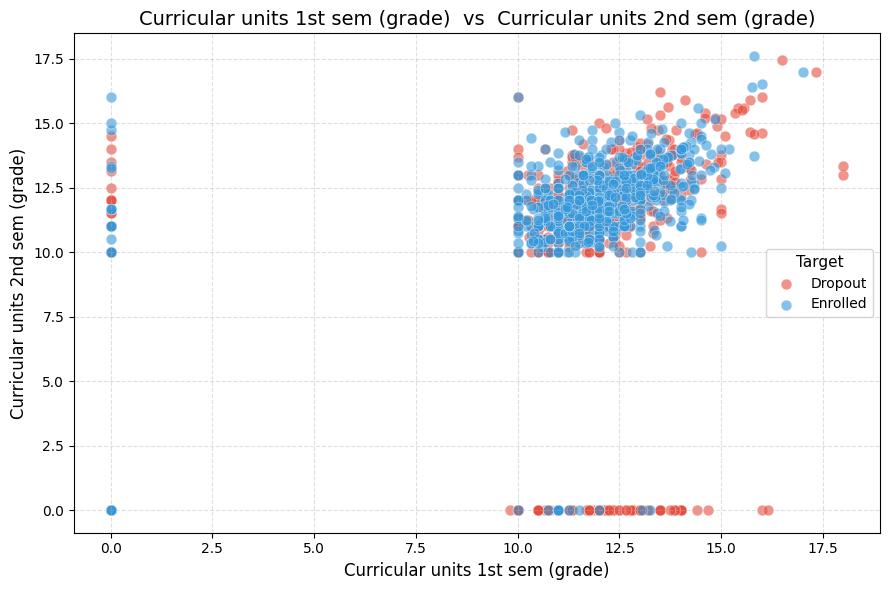

In [45]:
#scatter_plot_by_target(X_economia_limpia,'Curricular units 1st sem (grade)',
#       'Curricular units 2nd sem (grade)')
scatter_plot_by_target(X_economia_limpia[X_economia_limpia['Target'] != 'Graduate'],'Curricular units 1st sem (grade)',
       'Curricular units 2nd sem (grade)')

No hemos observado variaciones de importancia en los otros atributos medidos cuando quitamos a los deudores y a los que no pagan la cuota. Inferimos que todos los valores de los otros atributos se distribuyen en forma aproximadamente uniforme entre todas las situaciones económicas. En otras palabras, no se aprecia dependencias de los otros atributos respecto de la situación económica del estudiante.

Es el momento de establecer qué métricas de calidad usaremos antes de comenzar la experimentación con modelos predictivos en otro archivo. Para esto, recordamos las características del problema presentado: la universidad quiere interceptar a los estudiantes propensos a abandonar antes de que lo hagan. Les parece mucho más grave perder a un estudiante que intervenir con uno de que de todos modos no iba a abandonar. En términos de métricas, aunque haya 3 grupos, el peor error con diferencia es etiquetar casos 'Dropout' con cualquier otra categoría.
En segundo orden de prioridad, podemos poner el no etiquetar como 'Dropout' a quienes no lo son, para reducir el trabajo en intervenciones innecesarias.
Podríamos medir la calidad de predicción de las otras categorías, pero sin asignarle mucha importancia porque ni siquiera se nos ha planteado como objetivo.

Por eso, implementaremos las siguientes métricas, ordenadas por prioridad de mayor a menor:

1) El Recall TP/(TP+FN), donde consideramos positivos a los 'Dropout' y negativos al resto. Será más alto cuantos menos Dropout se nos escapen.

2) La Precision TP/(TP+FP), donde los positivos son nuevamente los 'Dropout'. Será más alto cuantas menos intervenciones innecesarias haya.

3) (si queda tiempo) La Accuracy, la proporción de casos correctamente clasificados sobre el total. Podemos usarla porque no hay un desbalance notorio de clases que la convierta en una mala métrica.

Elegiremos un modelo predictivo en primer lugar por tener mejor Recall, y por los siguientes criterios si esta métrica no muestra una diferencia notable.